### Note: This notebook is part 2 of 2.
Part 1, `01_data_cleaning.ipynb` creates `soo_locks_final_project_data.csv`, and this notebook will fail without that.

# Setup and data loading

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import mean_squared_error
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor
from sklearn.linear_model import LinearRegression
import seaborn as sns

# --- Configuration -----------------------------------------------------------
DATA_PATH = "soo_locks_final_project_data.csv"
RANDOM_STATE = 42
TEST_SIZE = 0.2
FOLDS = 5

# Skips the grid searches by default, since they already gave their optimal values
RUN_GRID_SEARCH = False 

df = pd.read_csv(DATA_PATH)
df

,VesselName,Length,Width,Date,Gate_Entry_Time,Gate_Exit_Time,Avg_Draft_Meters,Calculated_Cargo_Tons,Calculated_Hull_Weight_Tons,Lockage_Time_Minutes
0,CSL ST-LAURENT,225.50,23.79,2016-04-01,2016-04-01 00:52:43,2016-04-01 01:30:44,9.0,21244.0,21244.0,38.016667
1,PRESQUE ISLE,305.00,34.00,2016-04-01,2016-04-01 03:15:05,2016-04-01 03:53:33,6.8,20988.9,41065.2,38.466667
2,ALGOWOOD,225.55,23.19,2016-04-01,2016-04-01 06:02:52,2016-04-01 06:39:33,8.6,18871.7,20712.8,36.683333
3,CUYAHOGA,184.41,18.34,2016-04-01,2016-04-01 07:17:03,2016-04-01 07:50:54,7.6,9226.3,13393.0,33.850000
4,JOHN B AIRD,222.51,23.47,2016-04-01,2016-04-01 11:27:42,2016-04-01 12:20:34,8.6,18842.1,20680.3,52.866667
...,...,...,...,...,...,...,...,...,...,...
3152,JOETHOMPSON,215.00,22.00,2017-01-15,2017-01-15 13:51:29,2017-01-15 14:33:07,7.0,10406.0,18730.8,41.633333
3153,JOHN B AIRD,222.51,23.47,2017-01-15,2017-01-15 15:57:16,2017-01-15 16:40:17,8.6,18842.1,20680.3,43.016667
3154,MANITOULIN,138.90,23.03,2017-01-15,2017-01-15 18:55:50,2017-01-15 19:32:41,8.4,10978.5,12667.5,36.850000
3155,PRESQUE ISLE,305.00,34.00,2017-01-16,2017-01-16 03:00:54,2017-01-16 04:15:52,9.0,41065.2,41065.2,74.966667


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3157 entries, 0 to 3156
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   VesselName                   3157 non-null   object 
 1   Length                       3157 non-null   float64
 2   Width                        3157 non-null   float64
 3   Date                         3157 non-null   object 
 4   Gate_Entry_Time              3157 non-null   object 
 5   Gate_Exit_Time               3157 non-null   object 
 6   Avg_Draft_Meters             3157 non-null   float64
 7   Calculated_Cargo_Tons        3157 non-null   float64
 8   Calculated_Hull_Weight_Tons  3157 non-null   float64
 9   Lockage_Time_Minutes         3157 non-null   float64
dtypes: float64(6), object(4)
memory usage: 246.8+ KB


In [3]:
df.describe()

,Length,Width,Avg_Draft_Meters,Calculated_Cargo_Tons,Calculated_Hull_Weight_Tons,Lockage_Time_Minutes
count,3157.000000,3157.000000,3157.000000,3157.00000,3157.000000,3157.000000
mean,222.009252,24.292201,8.845154,24217.73438,23084.413525,44.330762
std,73.531320,6.211408,2.145630,14566.39510,11374.030154,13.011453
min,9.170000,3.200000,1.600000,0.00000,41.300000,10.166667
25%,195.000000,21.390000,8.000000,15031.90000,17796.800000,36.500000
50%,225.460000,23.700000,8.600000,21224.20000,20712.800000,41.000000
75%,304.810000,32.010000,9.800000,35203.10000,38637.600000,50.350000
max,330.000000,40.000000,14.800000,50816.40000,44431.200000,117.183333


# Feature Engineering

In [4]:
entry = pd.to_datetime(df['Gate_Entry_Time'])
df['Entry_Year']   = entry.dt.year
df['Entry_Month']  = entry.dt.month
df['Entry_Day']    = entry.dt.day
df['Entry_Hour']   = entry.dt.hour
df['Entry_Minute'] = entry.dt.minute
df

,VesselName,Length,Width,Date,Gate_Entry_Time,Gate_Exit_Time,Avg_Draft_Meters,Calculated_Cargo_Tons,Calculated_Hull_Weight_Tons,Lockage_Time_Minutes,Entry_Year,Entry_Month,Entry_Day,Entry_Hour,Entry_Minute
0,CSL ST-LAURENT,225.50,23.79,2016-04-01,2016-04-01 00:52:43,2016-04-01 01:30:44,9.0,21244.0,21244.0,38.016667,2016,4,1,0,52
1,PRESQUE ISLE,305.00,34.00,2016-04-01,2016-04-01 03:15:05,2016-04-01 03:53:33,6.8,20988.9,41065.2,38.466667,2016,4,1,3,15
2,ALGOWOOD,225.55,23.19,2016-04-01,2016-04-01 06:02:52,2016-04-01 06:39:33,8.6,18871.7,20712.8,36.683333,2016,4,1,6,2
3,CUYAHOGA,184.41,18.34,2016-04-01,2016-04-01 07:17:03,2016-04-01 07:50:54,7.6,9226.3,13393.0,33.850000,2016,4,1,7,17
4,JOHN B AIRD,222.51,23.47,2016-04-01,2016-04-01 11:27:42,2016-04-01 12:20:34,8.6,18842.1,20680.3,52.866667,2016,4,1,11,27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3152,JOETHOMPSON,215.00,22.00,2017-01-15,2017-01-15 13:51:29,2017-01-15 14:33:07,7.0,10406.0,18730.8,41.633333,2017,1,15,13,51
3153,JOHN B AIRD,222.51,23.47,2017-01-15,2017-01-15 15:57:16,2017-01-15 16:40:17,8.6,18842.1,20680.3,43.016667,2017,1,15,15,57
3154,MANITOULIN,138.90,23.03,2017-01-15,2017-01-15 18:55:50,2017-01-15 19:32:41,8.4,10978.5,12667.5,36.850000,2017,1,15,18,55
3155,PRESQUE ISLE,305.00,34.00,2017-01-16,2017-01-16 03:00:54,2017-01-16 04:15:52,9.0,41065.2,41065.2,74.966667,2017,1,16,3,0


In [5]:
df.drop(['Gate_Entry_Time','Gate_Exit_Time', 'Date','VesselName', 'Entry_Year', 'Entry_Minute'], axis=1, inplace=True)
# moving time to last column
df['Lockage_Time_Minutes'] = df.pop('Lockage_Time_Minutes')
df

,Length,Width,Avg_Draft_Meters,Calculated_Cargo_Tons,Calculated_Hull_Weight_Tons,Entry_Month,Entry_Day,Entry_Hour,Lockage_Time_Minutes
0,225.50,23.79,9.0,21244.0,21244.0,4,1,0,38.016667
1,305.00,34.00,6.8,20988.9,41065.2,4,1,3,38.466667
2,225.55,23.19,8.6,18871.7,20712.8,4,1,6,36.683333
3,184.41,18.34,7.6,9226.3,13393.0,4,1,7,33.850000
4,222.51,23.47,8.6,18842.1,20680.3,4,1,11,52.866667
...,...,...,...,...,...,...,...,...,...
3152,215.00,22.00,7.0,10406.0,18730.8,1,15,13,41.633333
3153,222.51,23.47,8.6,18842.1,20680.3,1,15,15,43.016667
3154,138.90,23.03,8.4,10978.5,12667.5,1,15,18,36.850000
3155,305.00,34.00,9.0,41065.2,41065.2,1,16,3,74.966667


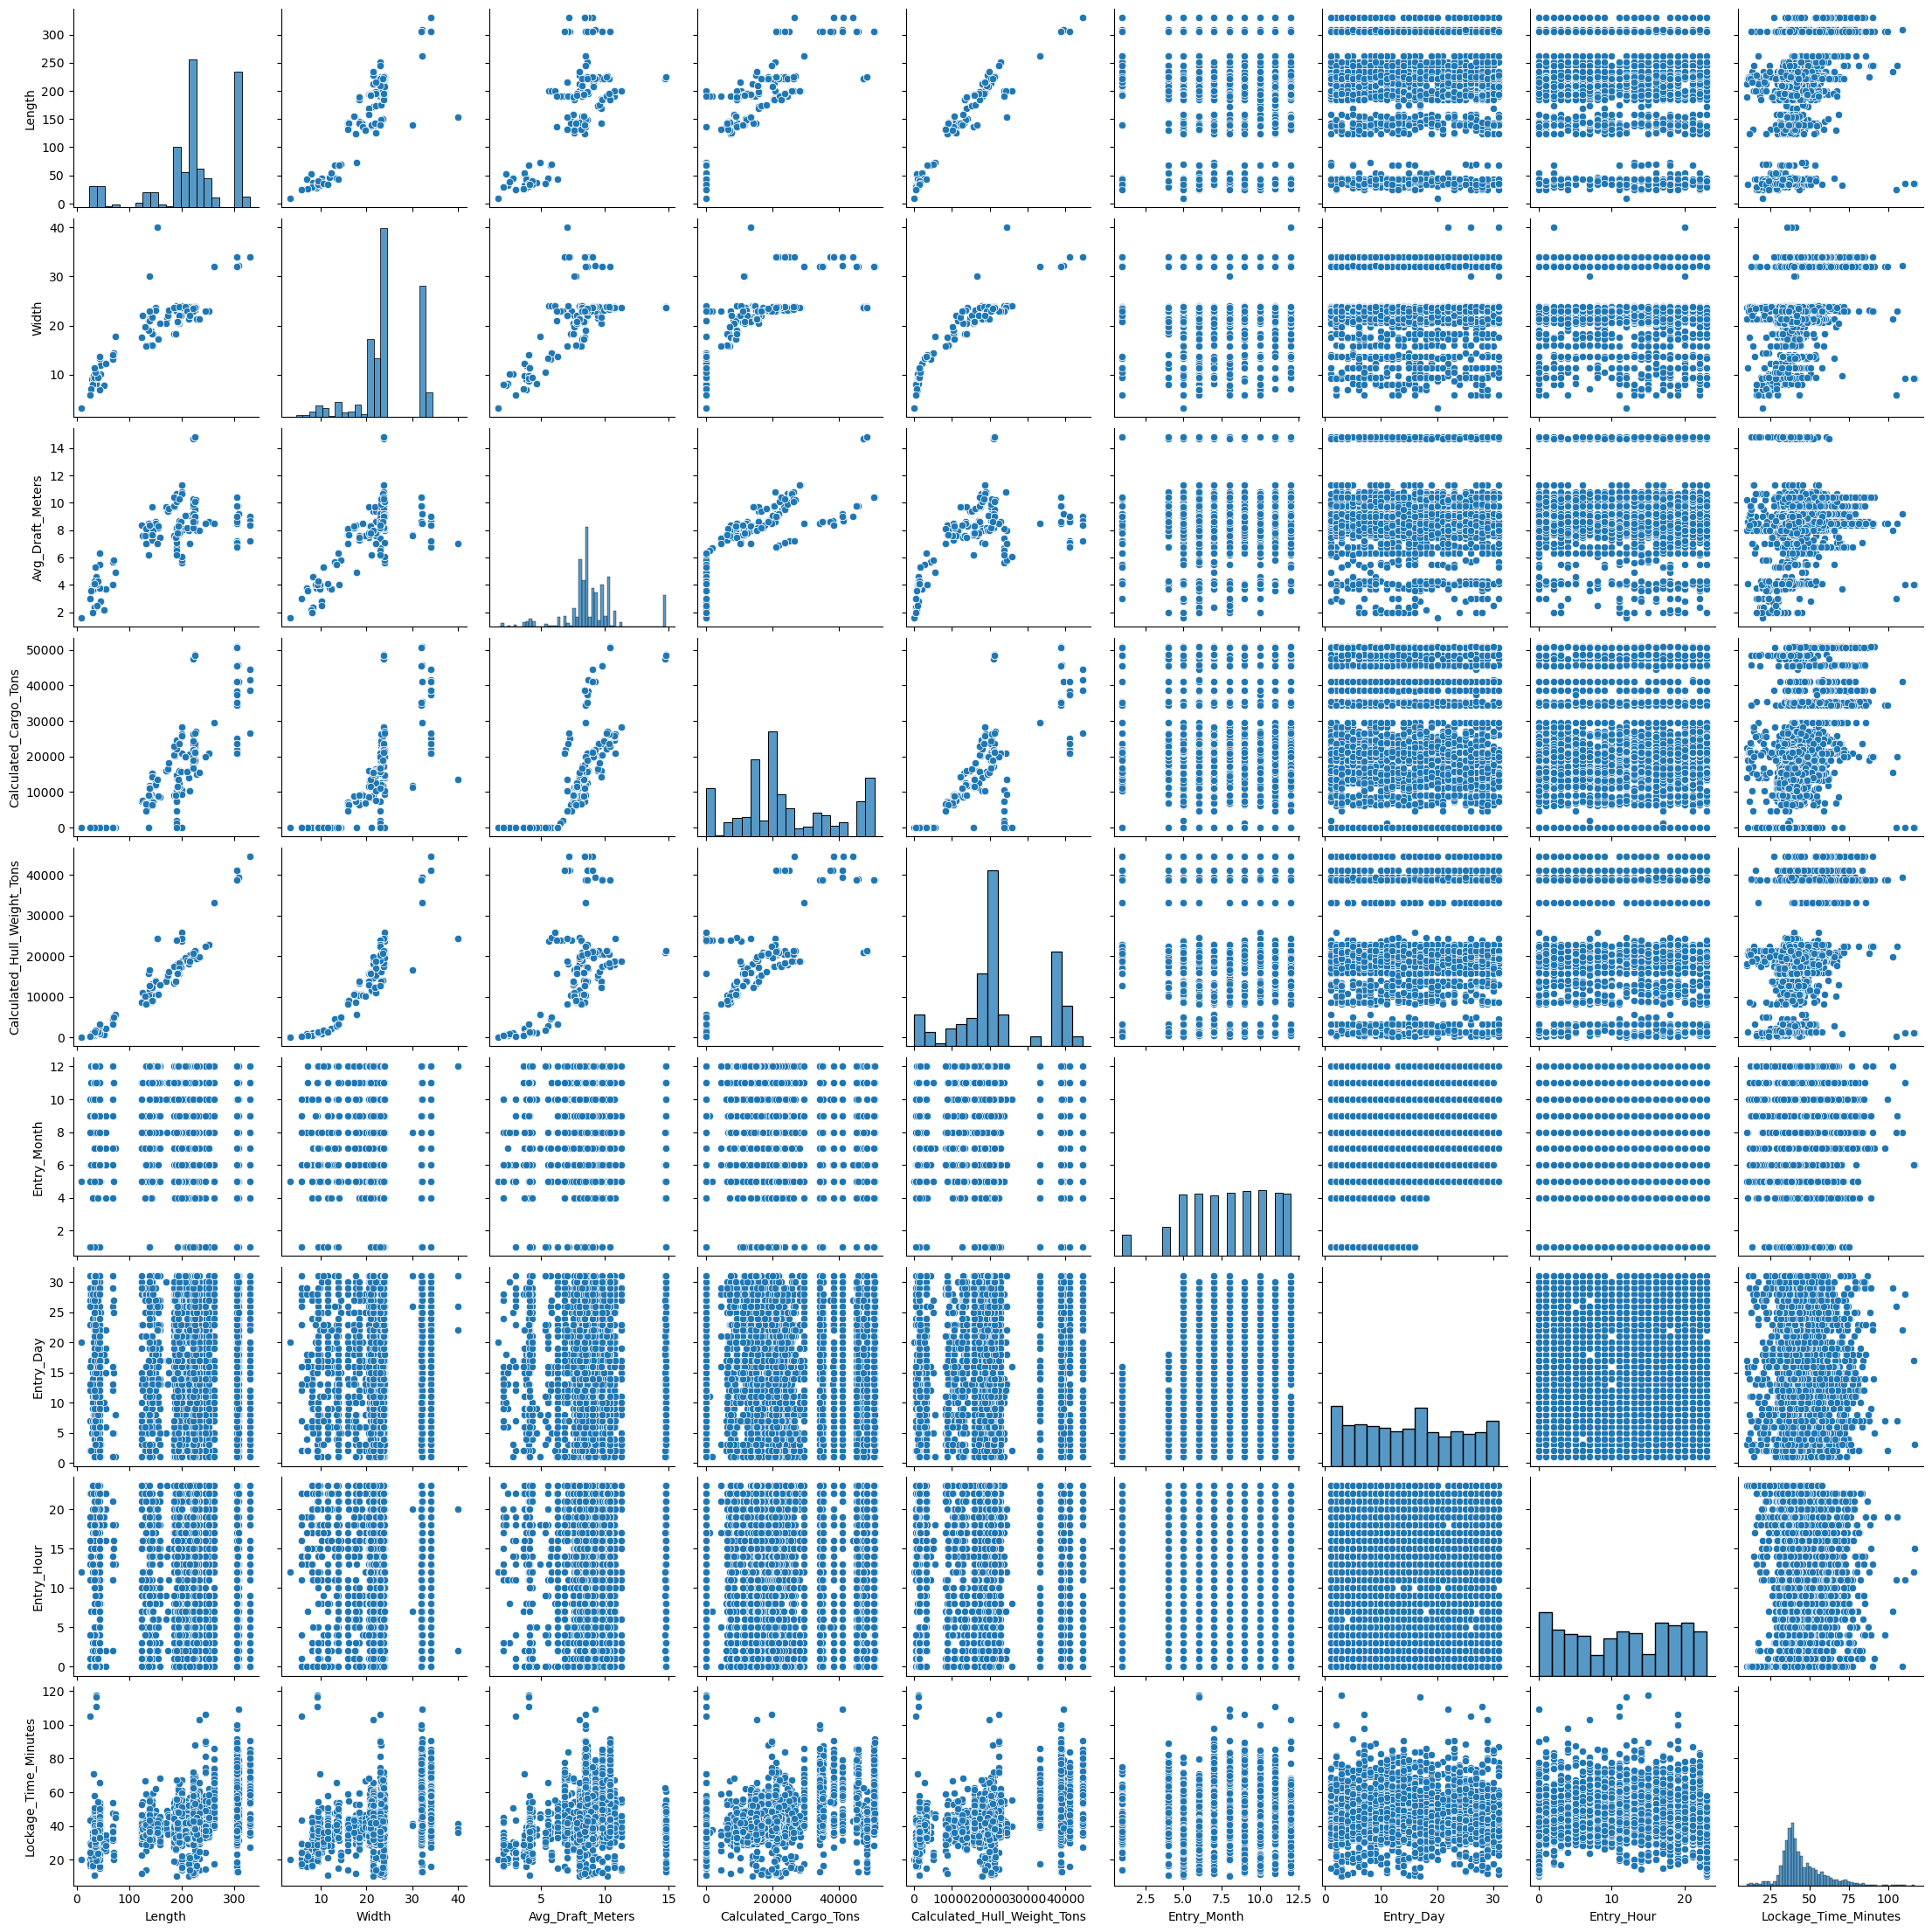

In [6]:
sns.pairplot(data=df)

**Findings.** 
- Most features tend to have multiple clusters of data when compared to Lockage_Time_Minutes.
- The features relating to size and weight show that smaller ships have a cluster near the top of the time scale, with many transits that take a long time, while also having a cluster near the bottom, with many transits that take comparatively little time.
- Meanwhile, as the ships get larger, the maximum time for any given size of ship also seems to get larger, though never to the extremes of the small ships.
- Times seem to have less of an affect on transit time, with the majority of the transit times being within a stable band across most month/day/etc, though each has outliers.

**Feature engineering results:**
Added:
- The Gate_Entry_Time column has been split into each of its component parts (Year, Month, Day, Hour, Minute)
Removed: 
- Gate_Entry_Time and Date, due to being redundant
- VesselName, since the name of vessel doesn't affect its speed
- Entry_Year, since it's either 2016 or 2017, since the data is over the course of one year
- Entry_Minute, due to mostly being noise
- Gate_Exit_Time, since that effectively gives the answer when paired with entry times

# Train-Test Split

In [7]:
X = df.iloc[:, :-1]   # every column except the last
y = df.iloc[:, -1]    # Lockage_Time_Minutes

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

In [8]:
# Evaluation helper
scores = {}
def report(name, model):
    """
    Takes in the model to report on and its name, printing the 
    cross-validated RMSE on the training set and the test data.
    Also saves results into scores to be accessed later.
    """
    cv_rmse = np.sqrt(-cross_val_score(model, X_train, y_train, cv=FOLDS,
                                     scoring='neg_mean_squared_error').mean())
    test_rmse = np.sqrt(mean_squared_error(y_test, model.predict(X_test)))
    scores[name] = {'CV RMSE': cv_rmse, 'Test RMSE': test_rmse}
    print(f"{name}: CV RMSE = {cv_rmse:.3f}, Test RMSE = {test_rmse:.3f}")


# Baseline: always predict the mean lockage time

In [9]:
report("Baseline (mean)", DummyRegressor().fit(X_train, y_train))

Baseline (mean): CV RMSE = 13.051, Test RMSE = 12.887


# Testing DecisionTreeRegressor

In [10]:
if RUN_GRID_SEARCH:
    params = {'max_depth': (3, 5, 7, 10, 15, None),
              'min_samples_leaf': (1, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100)}
            
    grid_tree = GridSearchCV(DecisionTreeRegressor(random_state=RANDOM_STATE), params,
                           cv=FOLDS, scoring='neg_mean_squared_error')
    grid_tree.fit(X_train, y_train)
    print(grid_tree.best_params_)
    report("Decision Tree", grid_tree.best_estimator_)

After running GridSearchCV on the decision tree regressor, the best parameters ended up as a max depth of 7 and min samples leaf of 40. I am leaving the grid search code in a False If statement so it doesn't need to be run again to run the regressor, but the variable can be set to True to run them again.

{'max_depth': 7, 'min_samples_leaf': 40}
Decision Tree: CV RMSE = 11.219, Test RMSE = 10.878

In [11]:
tree = DecisionTreeRegressor(max_depth=7, min_samples_leaf=40, random_state=RANDOM_STATE)
tree.fit(X_train, y_train)
report("Decision Tree", tree)

Decision Tree: CV RMSE = 11.219, Test RMSE = 10.878


# Testing BaggingRegressor

In [12]:
if RUN_GRID_SEARCH:
    params = {'estimator__min_samples_leaf': (1, 5, 10, 20),
            'max_samples': (0.25, 0.5, 0.75, 1.0),
            'n_estimators': (40, 60, 80, 110)}
            
    br = BaggingRegressor(estimator=DecisionTreeRegressor(), random_state=RANDOM_STATE)
    grid_bag = GridSearchCV(br, params, cv=FOLDS, scoring='neg_mean_squared_error')
    grid_bag.fit(X_train, y_train)
    print(grid_bag.best_params_)
    report("Bagging", grid_bag.best_estimator_)
    
    results = pd.DataFrame(grid_bag.cv_results_)
    results['rmse'] = np.sqrt(-results['mean_test_score'])
    display(results.sort_values('rmse')[['param_estimator__min_samples_leaf',
                               'param_max_samples', 'param_n_estimators',
                               'rmse']].head(10))

In [13]:
bag = BaggingRegressor(estimator=DecisionTreeRegressor(min_samples_leaf=5),
                       max_samples=0.25, n_estimators=110, random_state=RANDOM_STATE)
bag.fit(X_train, y_train)
report("Bagging", bag)

Bagging: CV RMSE = 11.010, Test RMSE = 10.711


I ran this with a grid search cross validation with:
- 'estimator__min_samples_leaf': (1, 5, 10, 20)
- 'max_samples': (0.25, 0.5, 0.75, 1.0)
- 'n_estimators': (40, 60, 80, 110)

I am choosing again to leave the grid search code in a False If statement and move forward with 5 for min samples leaf, 0.25 for max samples, and 110 for n estimators based on my initial grid search since they produced the best scores.

{'estimator__min_samples_leaf': 5, 'max_samples': 0.25, 'n_estimators': 110}
Bagging: CV RMSE = 11.010, Test RMSE = 10.711

# Testing LinearRegression

In [14]:
lin = LinearRegression()
lin.fit(X_train, y_train)
report("Linear Regression", lin)

Linear Regression: CV RMSE = 11.536, Test RMSE = 11.028


In [15]:
pd.DataFrame(scores).T.sort_values('CV RMSE')

,CV RMSE,Test RMSE
Bagging,11.009978,10.711263
Decision Tree,11.218968,10.877937
Linear Regression,11.535752,11.027621
Baseline (mean),13.050942,12.886652
